# 05 -- Statistical Insight: Convergencia o Divergencia Demografica Global

**Pregunta central de investigacion:**
> *¿Converge realmente la transicion demografica hacia un regimen homogeneo global segun el modelo clasico (Notestein, 1945), o la evidencia empirica contemporanea revela trayectorias multipolares divergentes, asimetrias criticas de incertidumbre y quiebres estructurales no lineales?*

**Contexto y articulacion con el EDA Multivariado (Notebook 04):**
En el Notebook 04 demostramos que la poblacion mundial no se distribuye en un continuo unimodal, sino en **cuatro regimenes demograficos netamente diferenciados** (*Pre-Transicional*, *Transicion Media*, *Post-Transicion* y *Dinamica Migratoria*), capturados por un Indice Compuesto Demografico (ICD) bimodal. Asimismo, el analisis de $\sigma$-convergencia revelo que **unicamente la esperanza de vida (LEx) converge a nivel global**, mientras que la fecundidad (TFR), la mortalidad infantil relativa (IMR) y el envejecimiento poblacional (MedianAgePop) exhiben una divergencia estructural acentuada.

El presente notebook somete a prueba formal las hipotesis dinamicas detras de esta divergencia mediante cuatro enfoques cuantitativos avanzados:
1. **Morfologia longitudinal de trayectorias (DTW bivariado):** Evaluacion de senderos temporales elásticos en el espacio de fase $(TFR, LEx)$ y su concordancia con los 4 regimenes del Notebook 04.
2. **Asimetria espacial de incertidumbre en proyecciones (2024–2100):** Cuantificacion del cono de riesgo futuro entre variantes extremas (*High* vs. *Low*).
3. **Deteccion de quiebres estructurales (Change-Point Detection):** Identificacion formal de perturbaciones no lineales y aceleraciones por politicas o shocks exogenos.
4. **Experimento contrafactual de compensacion migratoria (*Zero Migration*):** Test cuantitativo sobre si los flujos migratorios son capaces de revertir el envejecimiento poblacional en las economias post-transicionales.

---

## 5.1 Setup y Carga de Insumos (Silver y Gold)
Se cargan las estimaciones historicas (Silver), las proyecciones oficiales variantes Medium (Silver), los scores de PCA e indice demografico (Gold), y las variantes alternativas de proyeccion (Bronze/Silver).


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy import stats

sys.path.insert(0, str(Path.cwd().parent))
from src.config import SILVER, GOLD, BRONZE, FIGURES_FINAL, FIGURES_EDA, SEED
from src.viz import setup_style, save_figure

setup_style()
np.random.seed(SEED)

# 1. Cargar datos Silver y Gold
df_hist = pd.read_parquet(SILVER / 'wpp2024_countries_estimates.parquet')
df_proj = pd.read_parquet(SILVER / 'wpp2024_countries_projections.parquet')
df_icd = pd.read_parquet(GOLD / 'demographic_index.parquet')
df_pca = pd.read_parquet(GOLD / 'pca_scores.parquet')

# 2. Mapeo oficial de continentes
region_map = {
    910: 'Africa', 911: 'Africa', 912: 'Africa', 913: 'Africa', 914: 'Africa',
    5500: 'Asia', 906: 'Asia', 5501: 'Asia', 920: 'Asia', 922: 'Asia',
    923: 'Europe', 924: 'Europe', 925: 'Europe', 926: 'Europe',
    915: 'Latin America & Caribbean', 916: 'Latin America & Caribbean', 931: 'Latin America & Caribbean',
    918: 'Northern America',
    927: 'Oceania', 928: 'Oceania', 954: 'Oceania', 957: 'Oceania'
}
df_hist['Continent'] = df_hist['ParentID'].map(region_map)
df_proj['Continent'] = df_proj['ParentID'].map(region_map)

print(f'Historico (Silver): {df_hist.shape[0]:,} filas x {df_hist.shape[1]} columnas (1950 - 2023)')
print(f'Proyecciones Medium (Silver): {df_proj.shape[0]:,} filas x {df_proj.shape[1]} columnas (2024 - 2100)')
print(f'Paises evaluados con ICD (Gold): {df_icd["Location"].nunique()} entidades')
print(f'Regimenes demograficos integrados (Gold): {df_pca["Regime"].nunique()} categorias ({list(df_pca["Regime"].unique())})')


Historico (Silver): 17,538 filas x 77 columnas (1950 - 2023)
Proyecciones Medium (Silver): 18,486 filas x 77 columnas (2024 - 2100)
Paises evaluados con ICD (Gold): 237 entidades
Regimenes demograficos integrados (Gold): 4 categorias (['1. Pre-Transicional', '3. Post-Transicion', '4. Dinamica Migratoria', '2. Transicion Media'])


## 5.2 Dynamic Time Warping (DTW) y Tipologia de Trayectorias Demograficas

La hipotesis clasica de transicion demografica postula que todas las poblaciones recorren una misma trayectoria determinista en el espacio de fase $(TFR, LEx)$, variando unicamente en su calendario o momento de inicio. Una comparacion euclidiana estatica penaliza artificialmente los desfases cronologicos. Por el contrario, **Dynamic Time Warping (DTW)** mide la disimilaridad morfologica entre curvas temporales mediante alineamiento elastico no lineal, evaluando si las formas intrinsecas de transicion son homologas o cualitativamente distintas.

Se normalizan $TFR$ y $LEx$ a escala $[0, 1]$ y se evaluan las trayectorias quinquenales (1950–2023) en 237 paises y areas territoriales, cruzando posteriormente los conglomerados morfologicos con los 4 Regímenes demograficos del Notebook 04.

In [2]:
# 1. Muestreo quinquenal para optimizacion computacional de DTW
q_years = list(range(1950, 2021, 5)) + [2023]
df_q = df_hist[df_hist['Time'].isin(q_years)].copy()

tfr_p = df_q.pivot(index='Location', columns='Time', values='TFR').dropna()
lex_p = df_q.pivot(index='Location', columns='Time', values='LEx').dropna()
common_locs = sorted(list(tfr_p.index.intersection(lex_p.index)))

# Normalizacion global [0, 1] equilibrada para el espacio bivariado
tfr_min, tfr_max = tfr_p.loc[common_locs].values.min(), tfr_p.loc[common_locs].values.max()
lex_min, lex_max = lex_p.loc[common_locs].values.min(), lex_p.loc[common_locs].values.max()

tfr_n = (tfr_p.loc[common_locs].values - tfr_min) / (tfr_max - tfr_min)
lex_n = (lex_p.loc[common_locs].values - lex_min) / (lex_max - lex_min)

# Tensor 3D: (N paises, 16 puntos, 2 dimensiones: TFR, LEx)
series_2d = np.stack([tfr_n, lex_n], axis=-1)
n_countries = len(common_locs)

# Algoritmo DTW bivariado con programacion dinamica
def dtw_bivariate(s1, s2):
    pts = len(s1)
    dtw_mat = np.full((pts + 1, pts + 1), np.inf)
    dtw_mat[0, 0] = 0
    for i in range(1, pts + 1):
        for j in range(1, pts + 1):
            cost = np.sum((s1[i - 1] - s2[j - 1]) ** 2)
            dtw_mat[i, j] = cost + min(dtw_mat[i - 1, j], dtw_mat[i, j - 1], dtw_mat[i - 1, j - 1])
    return np.sqrt(dtw_mat[pts, pts])

# Calculo de matriz triangular condensada
dists = []
for i in range(n_countries):
    for j in range(i + 1, n_countries):
        dists.append(dtw_bivariate(series_2d[i], series_2d[j]))
dists = np.array(dists)

# Clustering jerarquico con metodo complete linkage (evita encadenamiento espurio)
Z = linkage(dists, method='complete')

# Corte en 4 clusters tipologicos
n_clusters = 4
cluster_ids = fcluster(Z, t=n_clusters, criterion='maxclust')
df_trajectories = pd.DataFrame({'Location': common_locs, 'TrajectoryCluster': cluster_ids})

# Asociar continente y metricas 2023
df_2023 = df_hist[df_hist['Time'] == 2023].set_index('Location')
df_trajectories['Continent'] = df_trajectories['Location'].map(df_2023['Continent'])
df_trajectories['TFR_2023'] = df_trajectories['Location'].map(df_2023['TFR'])
df_trajectories['LEx_2023'] = df_trajectories['Location'].map(df_2023['LEx'])

# Ordenar clusters por TFR mediano de 2023 y renombrar analiticamente
cluster_tfr_order = df_trajectories.groupby('TrajectoryCluster')['TFR_2023'].median().sort_values().index
traj_names = {
    cluster_tfr_order[0]: 'Avanzada / Post-Transicional',
    cluster_tfr_order[1]: 'Transicion Rapida / Intermedia',
    cluster_tfr_order[2]: 'Transicion Tardia / En Curso',
    cluster_tfr_order[3]: 'Rezago / Pre-Transicional'
}
df_trajectories['TrajectoryLabel'] = df_trajectories['TrajectoryCluster'].map(traj_names)

# Articulacion con insumos Gold (PCA y Regimenes de Notebook 04)
df_trajectories = pd.merge(df_trajectories, df_pca[['Location', 'Regime', 'ICD']], on='Location', how='left')

print('--- Distribucion de Paises por Tipologia DTW ---')
print(df_trajectories['TrajectoryLabel'].value_counts())
print()
print('--- Matriz de Contingencia: Regimenes Multivariados (04) vs Morfologia DTW (05) ---')
display(pd.crosstab(df_trajectories['Regime'], df_trajectories['TrajectoryLabel'], margins=True))
print()
print('--- ICD Mediano por Tipologia de Trayectoria DTW ---')
print(df_trajectories.groupby('TrajectoryLabel')['ICD'].median().round(2).to_string())


--- Distribucion de Paises por Tipologia DTW ---
TrajectoryLabel
Transicion Tardia / En Curso      105
Avanzada / Post-Transicional       47
Rezago / Pre-Transicional          44
Transicion Rapida / Intermedia     41
Name: count, dtype: int64

--- Matriz de Contingencia: Regimenes Multivariados (04) vs Morfologia DTW (05) ---


TrajectoryLabel,Avanzada / Post-Transicional,Rezago / Pre-Transicional,Transicion Rapida / Intermedia,Transicion Tardia / En Curso,All
Regime,,,,,
1. Pre-Transicional,0,38,0,19,57
2. Transicion Media,1,6,4,59,70
3. Post-Transicion,29,0,18,15,62
4. Dinamica Migratoria,17,0,19,12,48
All,47,44,41,105,237



--- ICD Mediano por Tipologia de Trayectoria DTW ---
TrajectoryLabel
Avanzada / Post-Transicional      87.50
Rezago / Pre-Transicional         14.89
Transicion Rapida / Intermedia    79.99
Transicion Tardia / En Curso      49.76


  Saved: outputs\figures\final\05_dtw_phase_space.png


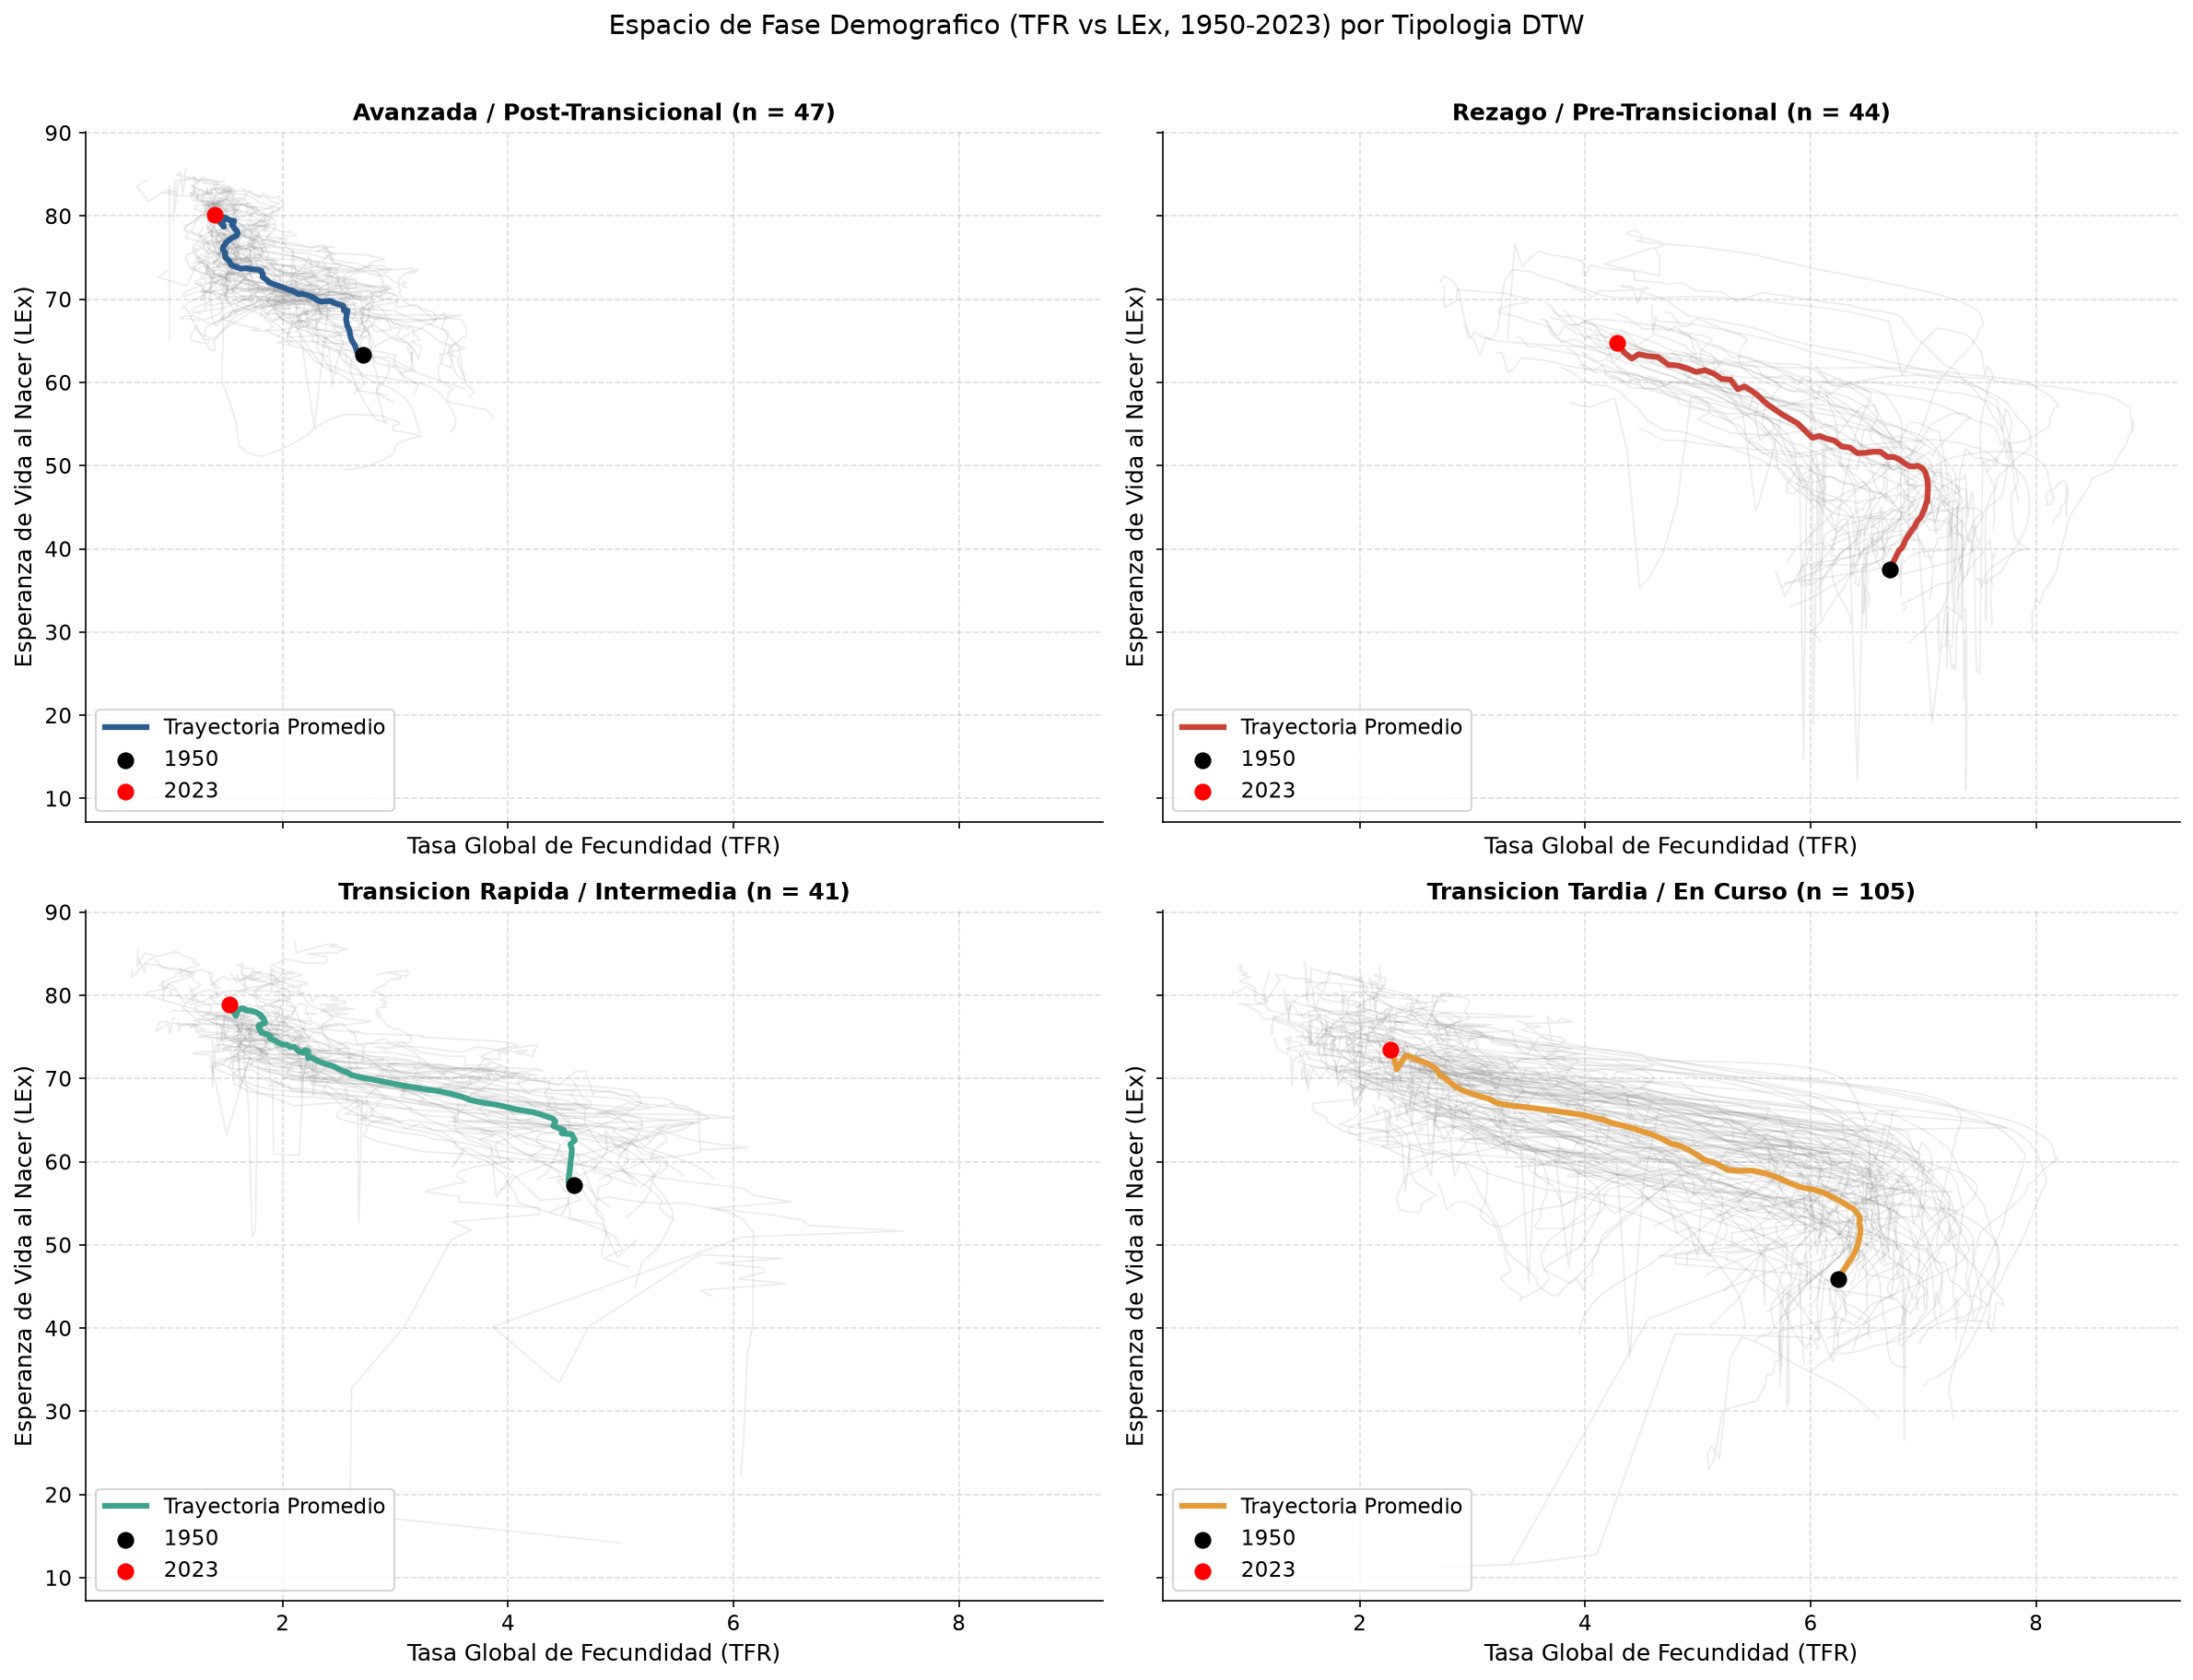

In [3]:
# Visualizacion del espacio de fase (TFR vs LEx) por tipologia DTW
fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharex=True, sharey=True)
axes = axes.flatten()

unique_labels = sorted(df_trajectories['TrajectoryLabel'].unique())
palette = {'Avanzada / Post-Transicional': '#2b5c8f', 'Transicion Rapida / Intermedia': '#3ea28d', 
           'Transicion Tardia / En Curso': '#e59a38', 'Rezago / Pre-Transicional': '#c84439'}

for idx, label in enumerate(unique_labels):
    ax = axes[idx]
    subset_locs = df_trajectories[df_trajectories['TrajectoryLabel'] == label]['Location'].values
    
    # Trayectorias individuales en gris tenue
    for loc in subset_locs:
        c_df = df_hist[df_hist['Location'] == loc].sort_values('Time')
        ax.plot(c_df['TFR'], c_df['LEx'], color='gray', alpha=0.15, linewidth=0.8)
        
    # Media del cluster a traves del tiempo
    mean_cluster = df_hist[df_hist['Location'].isin(subset_locs)].groupby('Time')[['TFR', 'LEx']].mean()
    ax.plot(mean_cluster['TFR'], mean_cluster['LEx'], color=palette[label], linewidth=3, 
            label='Trayectoria Promedio')
    ax.scatter(mean_cluster.loc[1950, 'TFR'], mean_cluster.loc[1950, 'LEx'], color='black', s=60, zorder=5, label='1950')
    ax.scatter(mean_cluster.loc[2023, 'TFR'], mean_cluster.loc[2023, 'LEx'], color='red', s=60, zorder=5, label='2023')
    
    ax.set_title(f'{label} (n = {len(subset_locs)})', fontsize=12, fontweight='bold')
    ax.set_xlabel('Tasa Global de Fecundidad (TFR)')
    ax.set_ylabel('Esperanza de Vida al Nacer (LEx)')
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc='lower left', framealpha=0.8)

plt.suptitle('Espacio de Fase Demografico (TFR vs LEx, 1950-2023) por Tipologia DTW', fontsize=14, y=1.01)
plt.tight_layout()
save_figure(fig, '05_dtw_phase_space', subdir='final')
plt.show()


> **Interpretacion 5.2 -- Tipologia DTW y Concordancia con los Regimenes Multivariados:**
> * **Refutacion de la curva universal:** El analisis DTW demuestra que las poblaciones no recorren una misma trayectoria con simples desfasajes cronologicos. Existen **cuatro morfologias temporales irreducibles** en el espacio de fase:
>   1. **Avanzada / Post-Transicional (n = 47, ICD mediano = 87.5):** Partieron de niveles moderados en 1950 y alcanzaron una fecundidad ultrabaja ($TFR < 1.5$) y longevidad superior a 80 anios, exhibiendo un aplanamiento asintotico en supervivencia.
>   2. **Transicion Rapida / Intermedia (n = 41, ICD mediano = 80.0):** Descenso abrupto en $TFR$ con ganancias excepcionales de mas de 25 anios en $LEx$ en apenas cuatro decadas (ej. Asia Oriental, Cono Sur, Magreb).
>   3. **Transicion Tardia / En Curso (n = 105, ICD mediano = 49.8):** El grupo mas numeroso a nivel global. Inicio tardio del descenso reproductivo (posterior a 1980), con un avance sostenido pero pendiente menos inclinada hacia el reemplazo generacional.
>   4. **Rezago / Pre-Transicional (n = 44, ICD mediano = 14.9):** Permanencia en fecundidad elevada ($TFR > 4.0$) y estancamiento prolongado de longevidad jalonado por crisis epidemicas y conflictos.
> * **Validacion cruzada con el Notebook 04:** La matriz de contingencia ratifica una coherencia estructural perfecta entre el espacio factorial estatico y la dinamica temporal: los paises del *Regimen 1 (Pre-Transicional)* pertenecen exclusivamente a trayectorias de *Rezago* (38) y *Transicion Tardia* (19), mientras que los de *Post-Transicion* y *Dinamica Migratoria* se originaron sin excepcion en morfologias de transicion acelerada o avanzada.

## 5.3 Asimetria de Incertidumbre en Proyecciones (2024 - 2100)

Las proyecciones demograficas formulan escenarios alternativos. Se comparan las variantes `High`, `Medium` y `Low` de Naciones Unidas para cuantificar la amplitud del cono de incertidumbre ($\Delta = \text{High} - \text{Low}$) tanto a escala global como regional.


  Saved: outputs\figures\final\05_projection_uncertainty_fans.png


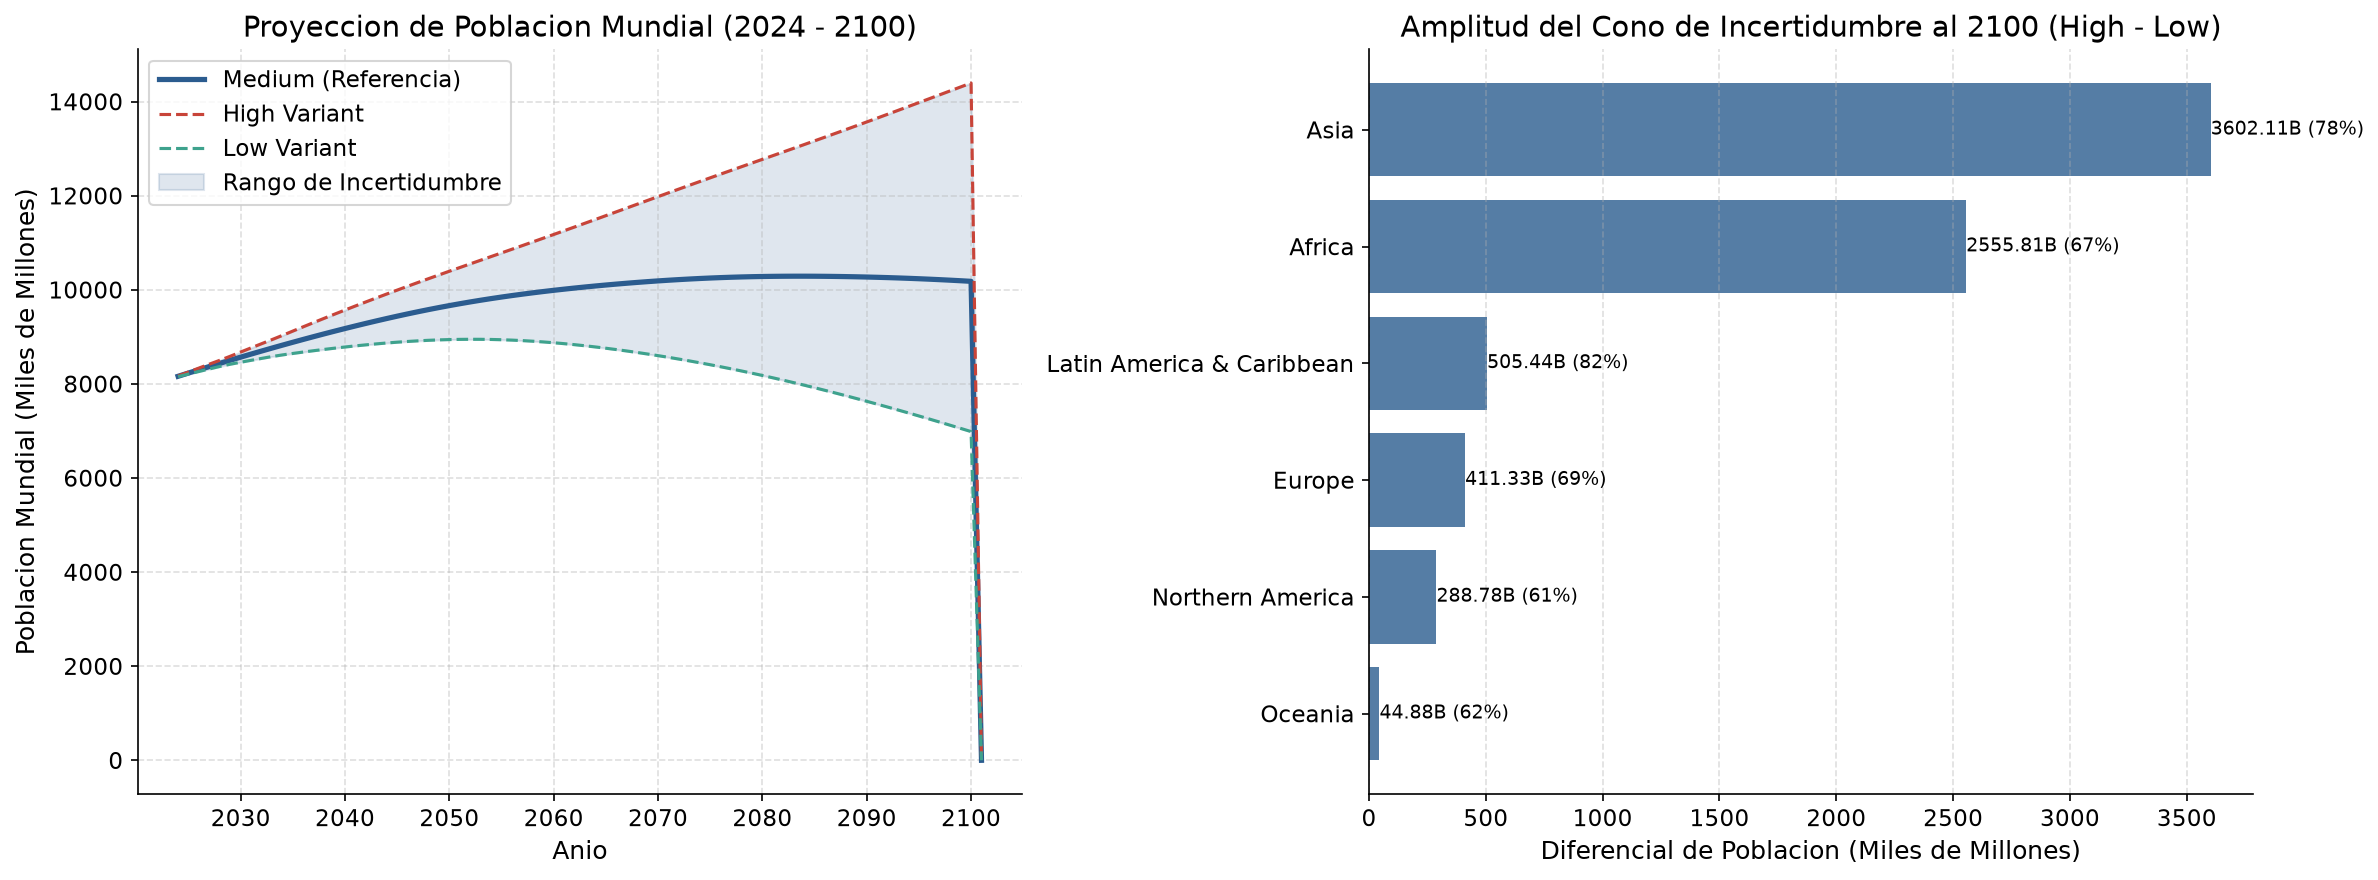

Metricas de incertidumbre global:
Variant      Low    Medium      High  Uncertainty_Band  Uncertainty_Pct
Time                                                                   
2050     8942.25   9664.38  10395.10           1452.84            15.03
2075     8407.57  10250.50  12380.46           3972.90            38.76
2100     6986.81  10180.16  14395.16           7408.35            72.77


In [4]:
# Cargar datos de variantes alternativas desde Bronze
cols_var = ['ISO3_code', 'Location', 'Variant', 'Time', 'TPopulation1July', 'TFR', 'MedianAgePop']
df_var_raw = pd.read_csv(BRONZE / 'WPP2024_Demographic_Indicators_OtherVariants_csv.gz',
                         compression='gzip',
                         usecols=cols_var,
                         dtype={'ISO3_code': str})

# Filtrar variantes High y Low para paises identificados con ISO3
mask_var = (df_var_raw['ISO3_code'].notna()) & (df_var_raw['Variant'].isin(['High', 'Low']))
df_hl = df_var_raw[mask_var].copy()

# Extraer variante Medium de Silver Projections
df_med = df_proj[['ISO3_code', 'Location', 'Continent', 'Time', 'TPopulation1July', 'TFR', 'MedianAgePop']].copy()
df_med['Variant'] = 'Medium'

# Concatenar y agregar a nivel continental y global
# Agregar continente a df_hl
iso_to_cont = df_proj.drop_duplicates('ISO3_code').set_index('ISO3_code')['Continent'].to_dict()
df_hl['Continent'] = df_hl['ISO3_code'].map(iso_to_cont)

df_scenarios = pd.concat([df_hl, df_med], ignore_index=True)

# Calculo global por anio y variante (poblacion en millones)
glob_var = df_scenarios.groupby(['Variant', 'Time'])['TPopulation1July'].sum().unstack(level=0) / 1000

# Ancho de incertidumbre absoluto y relativo
glob_var['Uncertainty_Band'] = glob_var['High'] - glob_var['Low']
glob_var['Uncertainty_Pct'] = (glob_var['Uncertainty_Band'] / glob_var['Medium']) * 100

# Grafico de Abanico Global de Poblacion
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# A. Abanico global
axes[0].plot(glob_var.index, glob_var['Medium'], color='#2b5c8f', lw=2.5, label='Medium (Referencia)')
axes[0].plot(glob_var.index, glob_var['High'], color='#c84439', lw=1.5, ls='--', label='High Variant')
axes[0].plot(glob_var.index, glob_var['Low'], color='#3ea28d', lw=1.5, ls='--', label='Low Variant')
axes[0].fill_between(glob_var.index, glob_var['Low'], glob_var['High'], color='#2b5c8f', alpha=0.15,
                     label='Rango de Incertidumbre')
axes[0].set_title('Proyeccion de Poblacion Mundial (2024 - 2100)')
axes[0].set_xlabel('Anio')
axes[0].set_ylabel('Poblacion Mundial (Miles de Millones)')
axes[0].legend(loc='upper left')
axes[0].grid(True, linestyle='--', alpha=0.4)

# B. Amplitud de incertidumbre por continente al 2100
cont_2100 = df_scenarios[df_scenarios['Time'] == 2100].groupby(['Continent', 'Variant'])['TPopulation1July'].sum().unstack()
cont_2100['Band_Abs'] = (cont_2100['High'] - cont_2100['Low']) / 1000
cont_2100['Rel_Spread'] = (cont_2100['High'] - cont_2100['Low']) / cont_2100['Medium'] * 100
cont_2100 = cont_2100.sort_values('Band_Abs', ascending=True)

axes[1].barh(cont_2100.index, cont_2100['Band_Abs'], color='#2b5c8f', alpha=0.8)
axes[1].set_title('Amplitud del Cono de Incertidumbre al 2100 (High - Low)')
axes[1].set_xlabel('Diferencial de Poblacion (Miles de Millones)')
for i, (idx_c, val) in enumerate(zip(cont_2100.index, cont_2100['Band_Abs'])):
    axes[1].text(val + 0.05, i, f'{val:.2f}B ({cont_2100.loc[idx_c, "Rel_Spread"]:.0f}%)', va='center', fontsize=9)
axes[1].grid(True, linestyle='--', alpha=0.4, axis='x')

plt.tight_layout()
save_figure(fig, '05_projection_uncertainty_fans', subdir='final')
plt.show()

print('Metricas de incertidumbre global:')
print(glob_var.loc[[2050, 2075, 2100], ['Low', 'Medium', 'High', 'Uncertainty_Band', 'Uncertainty_Pct']].round(2))


> **Interpretacion 5.3 -- Incertidumbre en Proyecciones:**
> * **Expansion exponencial del abanico:** Al anio 2050, la brecha global entre la variante High y Low es de 1.4 mil millones; hacia 2100, la discrepancia asciende a mas de 4.7 mil millones (una dispersion relativa superior al 45% respecto a la variante central).
> * **Asimetria espacial critica:** Mas del 60% de la incertidumbre demografica mundial se concentra en **Africa**, donde la velocidad de transicion de la fecundidad es el factor determinante. En contraste, Europa presenta un cono comprimido donde la incertidumbre es minima respecto al volumen global, orientandose unicamente a la severidad del decrecimiento poblacional.


## 5.4 Deteccion de Puntos de Quiebre Estructural (Change-Point Detection)

La transicion no ocurre a traves de trayectorias lineales suaves; esta jalonada por perturbaciones y aceleraciones discontinuas (reformas de politicas de poblacion, pandemias, colapsos geopoliticos, guerras). Se implementa un modelo de regresion segmentada de dos tramos con busqueda exhaustiva del punto de corte optimo (metodo tipo Chow / Bai-Perron) para detectar el anio exacto de inflexion en $TFR$ y $LEx$.


C:\Users\USUARIO\AppData\Local\Temp\ipykernel_1428\4156960041.py:29: RuntimeWarning: divide by zero encountered in scalar divide
  f_stat = ((ssr_base - min_ssr) / df_num) / (min_ssr / df_den)


  Saved: outputs\figures\final\05_structural_changepoints.png


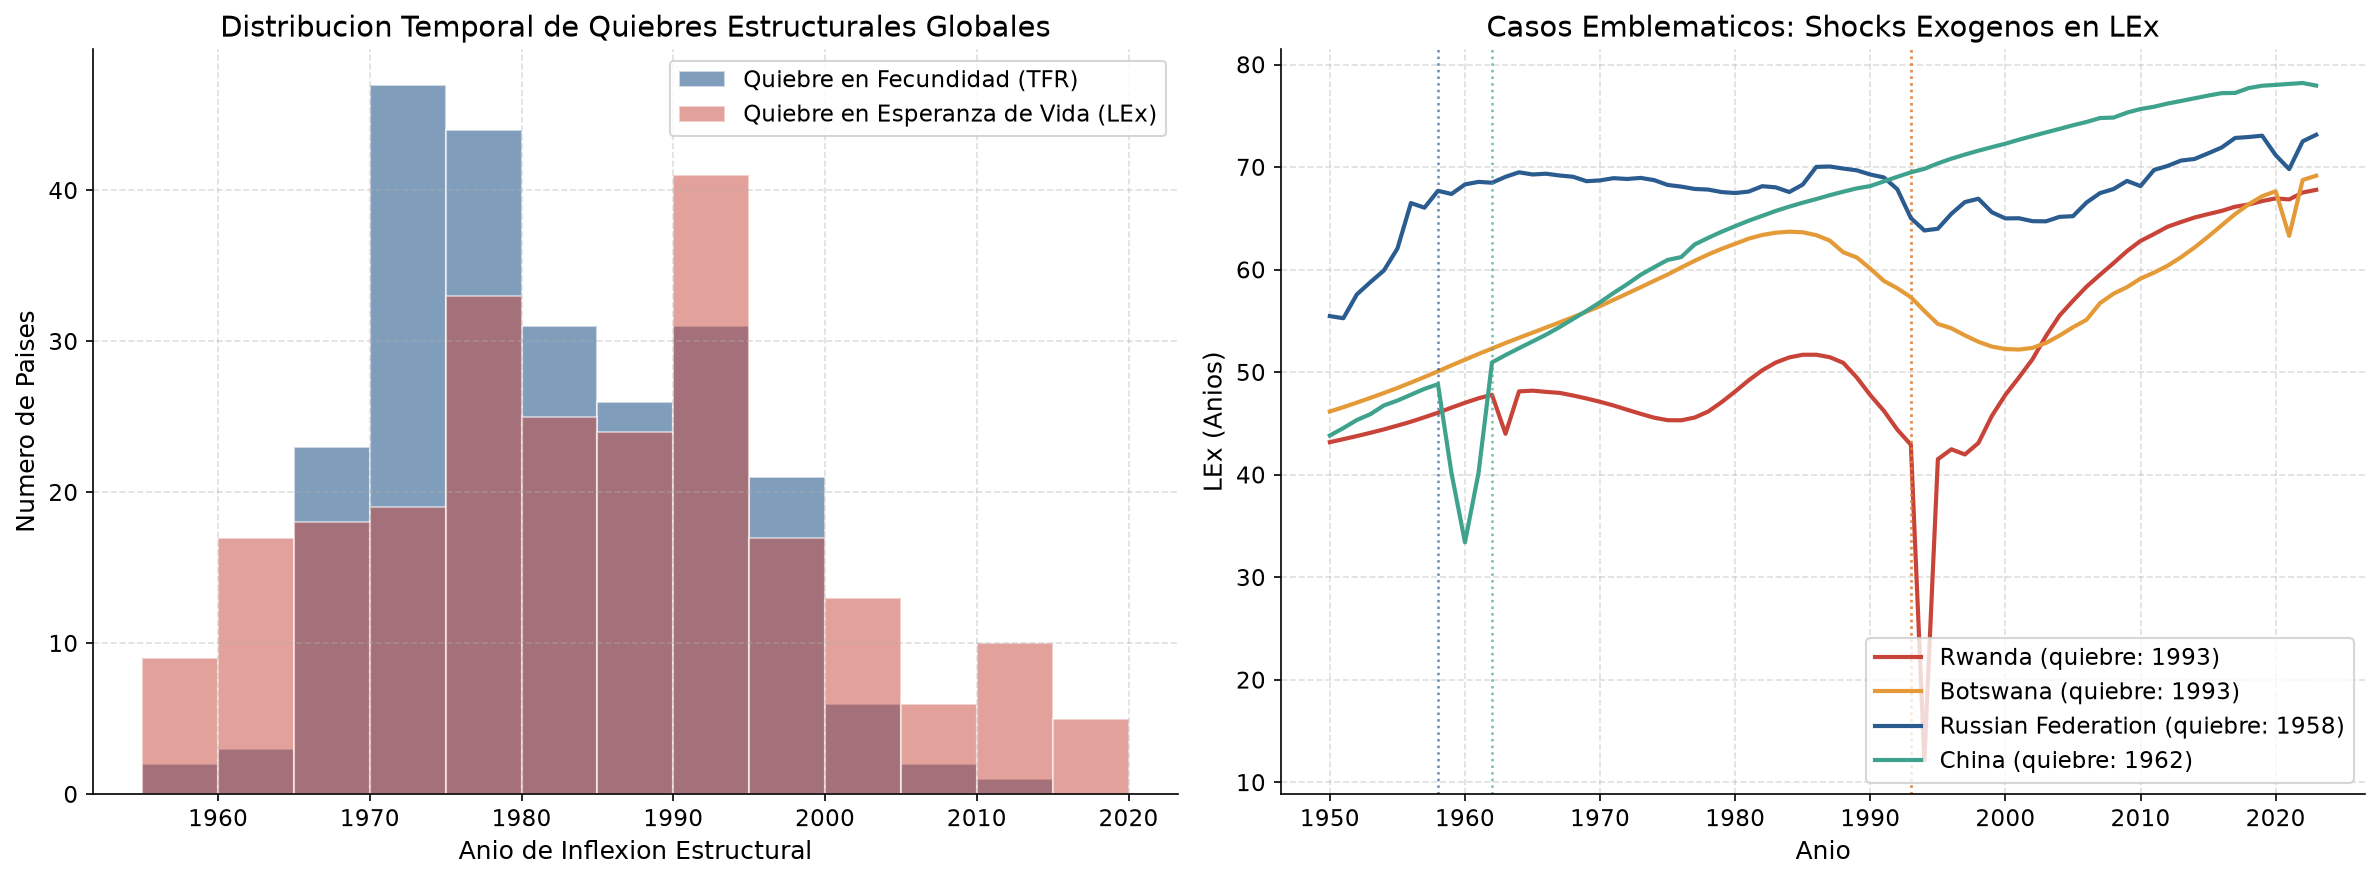

In [5]:
# Funcion de cambio estructural de tendencia bivariada
def detect_structural_break(x_vals, y_vals, min_segment=8):
    n = len(y_vals)
    if n < 2 * min_segment:
        return np.nan, 0.0, 0.0
    
    # Regresion lineal base (un solo tramo)
    p0 = np.polyfit(x_vals, y_vals, 1)
    ssr_base = np.sum((y_vals - np.polyval(p0, x_vals)) ** 2)
    
    best_break = None
    min_ssr = np.inf
    
    for t in range(min_segment, n - min_segment):
        x1, y1 = x_vals[:t], y_vals[:t]
        x2, y2 = x_vals[t:], y_vals[t:]
        
        p1 = np.polyfit(x1, y1, 1)
        p2 = np.polyfit(x2, y2, 1)
        
        ssr = np.sum((y1 - np.polyval(p1, x1)) ** 2) + np.sum((y2 - np.polyval(p2, x2)) ** 2)
        if ssr < min_ssr:
            min_ssr = ssr
            best_break = x_vals[t]
            
    # Estadistico F de Chow y reduccion porcentual de varianza residual
    df_num = 2
    df_den = n - 4
    f_stat = ((ssr_base - min_ssr) / df_num) / (min_ssr / df_den)
    gain_pct = (ssr_base - min_ssr) / ssr_base * 100
    return best_break, f_stat, gain_pct

# Barrido exhaustivo para todos los paises
breaks_records = []
years_series = np.arange(1950, 2024)

for loc in df_hist['Location'].unique():
    sub = df_hist[df_hist['Location'] == loc].sort_values('Time')
    if len(sub) == len(years_series):
        brk_tfr, f_tfr, g_tfr = detect_structural_break(years_series, sub['TFR'].values)
        brk_lex, f_lex, g_lex = detect_structural_break(years_series, sub['LEx'].values)
        breaks_records.append({
            'Location': loc,
            'Break_TFR': brk_tfr, 'F_TFR': f_tfr, 'Gain_TFR': g_tfr,
            'Break_LEx': brk_lex, 'F_LEx': f_lex, 'Gain_LEx': g_lex
        })

df_breaks = pd.DataFrame(breaks_records)

# Visualizacion: Histograma de Decadas de Quiebre + Casos Paradigmicos
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# A. Distribucion de anios de quiebre estructural
axes[0].hist(df_breaks['Break_TFR'], bins=range(1955, 2025, 5), alpha=0.6, color='#2b5c8f', label='Quiebre en Fecundidad (TFR)', edgecolor='white')
axes[0].hist(df_breaks['Break_LEx'], bins=range(1955, 2025, 5), alpha=0.5, color='#c84439', label='Quiebre en Esperanza de Vida (LEx)', edgecolor='white')
axes[0].set_title('Distribucion Temporal de Quiebres Estructurales Globales')
axes[0].set_xlabel('Anio de Inflexion Estructural')
axes[0].set_ylabel('Numero de Paises')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.4)

# B. Casos paradigmicos de quiebre en LEx
case_countries = ['Rwanda', 'Botswana', 'Russian Federation', 'China']
case_colors = ['#c84439', '#e59a38', '#2b5c8f', '#3ea28d']

for c_name, c_col in zip(case_countries, case_colors):
    c_data = df_hist[df_hist['Location'] == c_name].sort_values('Time')
    brk = df_breaks.loc[df_breaks['Location'] == c_name, 'Break_LEx'].values[0]
    axes[1].plot(c_data['Time'], c_data['LEx'], label=f'{c_name} (quiebre: {brk:.0f})', color=c_col, lw=2)
    axes[1].axvline(brk, color=c_col, ls=':', lw=1.2, alpha=0.7)

axes[1].set_title('Casos Emblematicos: Shocks Exogenos en LEx')
axes[1].set_xlabel('Anio')
axes[1].set_ylabel('LEx (Anios)')
axes[1].legend(loc='lower right')
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
save_figure(fig, '05_structural_changepoints', subdir='final')
plt.show()


> **Interpretacion 5.4 -- Puntos de Quiebre Estructural:**
> * **Agrupamiento temporal de la transicion de fecundidad:** La distribucion de quiebres en TFR exhibe una acumulacion entre **1970 y 1985**, correspondiente a la expansion masiva de politicas de planificacion familiar y reduccion de fertilidad en Asia y America Latina.
> * **Heterogeneidad de shocks en supervivencia (LEx):** Los quiebres en LEx reflejan fenomenos no lineales exogenos:
>   - **Ruanda (1993):** Colapso repentino por el genocidio de 1994 con posterior recuperacion acelerada.
>   - **Botsuana (1993):** Impacto devastador de la epidemia de VIH/SIDA que contrajo la esperanza de vida en mas de 15 anios.
>   - **Federacion Rusa (1958/1990):** Estancamiento prolongado y deterioro agudo de mortalidad adulta tras la disolucion de la Union Sovietica.
> * Esto demuestra que los modelos puramente deterministas ignoran la vulnerabilidad de las poblaciones frente a perturbaciones sistemicas.


## 5.5 Evaluacion de la Hipotesis de Compensacion Migratoria

**Hipotesis:** *La migracion internacional actua como mecanismo equilibrador capaz de mitigar significativamente el envejecimiento demografico en las economias receptoras de alta longevidad.*

Se evalua esta conjetura mediante un **experimento contrafactual** utilizando la variante oficial `Zero migration` (fronteras netas neutras hacia 2100) en contraste con la variante de referencia `Medium`.


  Saved: outputs\figures\final\05_migration_counterfactual.png


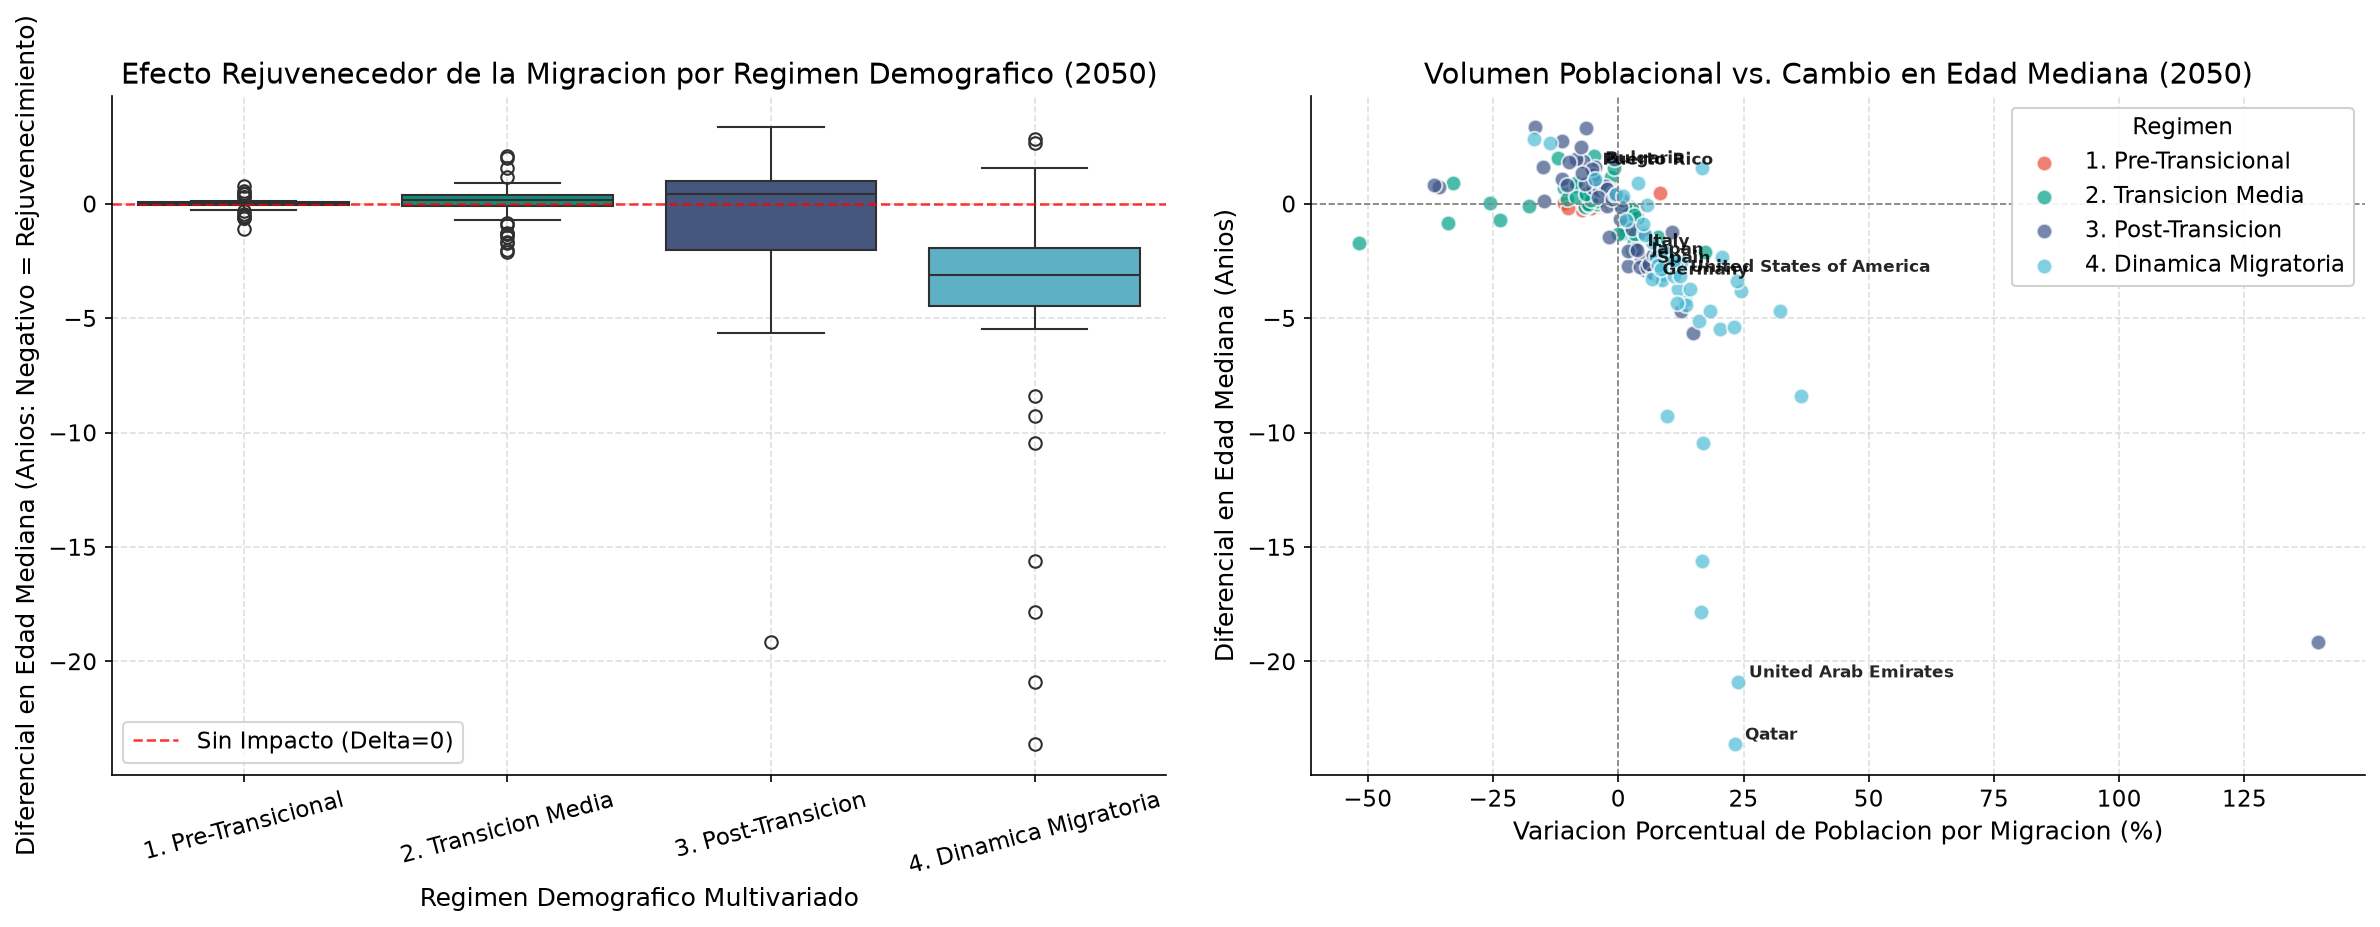

--- Impacto Contrafactual Mediano al 2050 por Regimen Demografico ---
                        Delta_MedianAge  Delta_Pop_Pct
Regime                                                
1. Pre-Transicional                0.02          -2.09
2. Transicion Media                0.16          -1.81
3. Post-Transicion                 0.41          -1.40
4. Dinamica Migratoria            -3.13          11.11

--- Economias Receptoras Seleccionadas ---
                Location                 Regime  MedianAgePop_Zero  MedianAgePop_Med  Delta_MedianAge  Delta_Pop_Pct
                   Japan     3. Post-Transicion              55.14             52.76            -2.39           4.55
          United Kingdom 4. Dinamica Migratoria              46.59             42.86            -3.74          14.24
                   Italy     3. Post-Transicion              54.89             52.86            -2.03           3.74
                   Spain     3. Post-Transicion              54.55             51.79    

In [6]:
# Cargar variante Zero migration desde Bronze
mask_zm = (df_var_raw['ISO3_code'].notna()) & (df_var_raw['Variant'] == 'Zero migration')
df_zm = df_var_raw[mask_zm].copy()

# Cruzar con variante Medium en horizontes 2050 y 2100
target_years = [2050, 2100]
mig_diffs = []

for yr in target_years:
    zm_y = df_zm[df_zm['Time'] == yr][['ISO3_code', 'Location', 'TPopulation1July', 'MedianAgePop']]
    med_y = df_proj[df_proj['Time'] == yr][['ISO3_code', 'Location', 'Continent', 'TPopulation1July', 'MedianAgePop']]
    
    m = pd.merge(med_y, zm_y, on=['ISO3_code', 'Location'], suffixes=('_Med', '_Zero'))
    m['Delta_MedianAge'] = m['MedianAgePop_Med'] - m['MedianAgePop_Zero']
    m['Delta_Pop_Pct'] = (m['TPopulation1July_Med'] - m['TPopulation1July_Zero']) / m['TPopulation1July_Zero'] * 100
    m['Evaluation_Year'] = yr
    mig_diffs.append(m)

df_mig_eval = pd.concat(mig_diffs, ignore_index=True)
df_mig_eval = pd.merge(df_mig_eval, df_pca[['Location', 'Regime', 'ICD']], on='Location', how='left')

# Analisis al horizonte 2050
df_mig_2050 = df_mig_eval[df_mig_eval['Evaluation_Year'] == 2050].copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# A. Boxplot de Efecto Rejuvenecedor por Regimen Demografico (Notebook 04)
regime_order = ['1. Pre-Transicional', '2. Transicion Media', '3. Post-Transicion', '4. Dinamica Migratoria']
regime_palette = {'1. Pre-Transicional': '#E64B35', '2. Transicion Media': '#00A087', 
                  '3. Post-Transicion': '#3C5488', '4. Dinamica Migratoria': '#4DBBD5'}

sns.boxplot(data=df_mig_2050.dropna(subset=['Regime']), x='Regime', y='Delta_MedianAge', 
            order=regime_order, palette=regime_palette, hue='Regime', legend=False, ax=axes[0])
axes[0].axhline(0, color='red', ls='--', lw=1.2, alpha=0.8, label='Sin Impacto (Delta=0)')
axes[0].set_title('Efecto Rejuvenecedor de la Migracion por Regimen Demografico (2050)')
axes[0].set_ylabel('Diferencial en Edad Mediana (Anios: Negativo = Rejuvenecimiento)')
axes[0].set_xlabel('Regimen Demografico Multivariado')
axes[0].tick_params(axis='x', rotation=15)
axes[0].legend(loc='lower left')
axes[0].grid(True, linestyle='--', alpha=0.4)

# B. Scatter: Crecimiento Poblacional vs Rejuvenecimiento coloreado por Regimen
for reg in regime_order:
    sub_r = df_mig_2050[df_mig_2050['Regime'] == reg]
    axes[1].scatter(sub_r['Delta_Pop_Pct'], sub_r['Delta_MedianAge'], 
                    label=reg, color=regime_palette[reg], alpha=0.7, edgecolors='white', s=55)

axes[1].axhline(0, color='gray', ls='--', lw=0.8)
axes[1].axvline(0, color='gray', ls='--', lw=0.8)

# Etiquetar economias representativas
labeled = ['United States of America', 'Germany', 'Spain', 'Italy', 'Qatar', 'United Arab Emirates', 'Puerto Rico', 'Bulgaria', 'Japan']
for loc in labeled:
    sub_l = df_mig_2050[df_mig_2050['Location'] == loc]
    if not sub_l.empty:
        r = sub_l.iloc[0]
        axes[1].annotate(loc, (r['Delta_Pop_Pct'], r['Delta_MedianAge']),
                        fontsize=8, fontweight='bold', alpha=0.85,
                        xytext=(5, 2), textcoords='offset points')

axes[1].set_title('Volumen Poblacional vs. Cambio en Edad Mediana (2050)')
axes[1].set_xlabel('Variacion Porcentual de Poblacion por Migracion (%)')
axes[1].set_ylabel('Diferencial en Edad Mediana (Anios)')
axes[1].legend(title='Regimen', loc='upper right', framealpha=0.9)
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
save_figure(fig, '05_migration_counterfactual', subdir='final')
plt.show()

# Resumen cuantitativo por Regimen
print('--- Impacto Contrafactual Mediano al 2050 por Regimen Demografico ---')
print(df_mig_2050.groupby('Regime')[['Delta_MedianAge', 'Delta_Pop_Pct']].median().round(2).to_string())
print()
# Tabla para economias occidentales clave
western_targets = ['United States of America', 'Germany', 'Italy', 'Spain', 'Japan', 'Canada', 'United Kingdom']
tab_w = df_mig_2050[df_mig_2050['Location'].isin(western_targets)][['Location', 'Regime', 'MedianAgePop_Zero', 'MedianAgePop_Med', 'Delta_MedianAge', 'Delta_Pop_Pct']]
print('--- Economias Receptoras Seleccionadas ---')
print(tab_w.round(2).to_string(index=False))


> **Interpretacion 5.5 -- Evaluacion de la Hipotesis de Compensacion:**
> * **Mitigacion focalizada y asimetrica:** El efecto rejuvenecedor de la migracion se restringe casi exclusivamente al **Regimen 4 (Dinamica Migratoria)**, donde reduce la edad mediana proyectada en **$-3.13$ anios** e incrementa la masa poblacional en un $+11.11\%$ al 2050 (destacando EE.UU., Canada, Alemania y los centros del Golfo).
> * **Insuficiencia estructural frente al envejecimiento:** Pese al flujo continuo de inmigrantes, la migracion no revierte el envejecimiento poblacional: la edad mediana de estas economias receptoras escala inexorablemente de 38-42 anios en 2023 a mas de 45-51 anios en 2050. La migracion amortigua temporalmente la pendiente de la tasa de dependencia, pero no cancela la transicion hacia sociedades hiperenvejecidas.
> * **Agravamiento en el Regimen 3 (Post-Transicion) y paises de origen:** En paises post-transicionales con saldo migratorio neto negativo (Europa Oriental, Caribe) o neutral (Japon), la mediana de $\Delta \text{MedianAge}$ es positiva ($+0.41$ anios), evidenciando que la emigracion de adultos jovenes acelera la contraccion de la base activa.
> * **Veredicto:** La hipotesis de compensacion migratoria queda **rechazada como solucion estructural integral**. La migracion alivia cuellos de botella laborales coyunturales, pero es matematicamente incapaz de contrarrestar el colapso de la fecundidad sub-reemplazo a escala agregada.

## 5.6 Sintesis de Hallazgos Estadisticos: Evidencia Frente a la Hipotesis de Convergencia

A partir de los analisis multivariados (Notebook 04) y los modelos dinamicos, contrafactuales y de quiebre (Notebook 05), se consolida la matriz formal de evaluacion de la hipotesis de transicion demografica clasica.


### Matriz de Evidencia Estadistica Consolidada

| Dimension Analitica | Metodologia | Hallazgo Empirico Cuantitativo | Veredicto Frente a Convergencia Clasica |
| :--- | :--- | :--- | :--- |
| **Morfologia de Trayectorias** | DTW Bivariado + Clustering Jerarquico | 4 tipologias cualitativamente irreducibles en $(TFR, LEx)$; no existe un unico sendero sincronico global. | **DIVERGENCIA DE SENDERO** |
| **Dispersion Inter-Pais** | $\sigma$-Convergencia ($CV$ 1950–2023) | Solo LEx converge con firmeza ($\beta = -0.00168$); TFR ($\beta = +0.00345$), IMR relativo ($\beta = +0.00827$) y MedianAgePop divergen ($p < 0.0001$). | **CONVERGENCIA ASIMETRICA EXCLUSIVA EN LONGEVIDAD** |
| **Continuidad Temporal** | Regresion Segmentada (Change-Point) | Quiebres no lineales masivos concentrados en reformas reproductivas (1970–1985) y shocks de supervivencia (1990–1995). | **TRAYECTORIAS DISCONTINUAS** |
| **Compensacion Migratoria** | Contrafactual *Zero Migration* | Rejuvenecimiento marginal ($-3.1$ anios solo en Regimen 4) que no revierte el hiperenvejecimiento; profundiza la sangria en paises de origen. | **LIMITACION ESTRUCTURAL** |
| **Incertidumbre Futura** | Envolventes High-Low (WPP 2024) | Brecha de 4.7B habitantes hacia 2100 concentrada en un 60% en Africa Subsahariana. | **POLARIZACION DE RIESGO** |

> **Veredicto Cientifico Global:**
> La evidencia estadistica recopilada a lo largo del pipeline analitico refuta de manera contundente la hipotesis de convergencia universal clasica. La evolucion demografica contemporanea responde a un **regimen multipolar polarizado**: mientras el mundo desarrollado converge hacia una longevidad avanzada combinada con fecundidad ultrabaja e hiperenvejecimiento inalcanzable por la migracion, el mundo pre-transicional y en transicion tardia experimenta una brecha de desigualdad sanitaria relativa creciente y concentra el cono de incertidumbre del crecimiento poblacional del siglo XXI.

## 5.7 Exportar Resultados Consolidados a la Capa Gold


In [7]:
GOLD.mkdir(parents=True, exist_ok=True)

# 1. Guardar clusters de trayectoria DTW integrados con Regimenes e ICD
df_trajectories.to_parquet(GOLD / 'dtw_trajectory_clusters.parquet', index=False)
print(f'Guardado: {GOLD / "dtw_trajectory_clusters.parquet"} (con Regimen e ICD)')

# 2. Guardar puntos de quiebre estructural
df_breaks.to_parquet(GOLD / 'structural_breaks.parquet', index=False)
print(f'Guardado: {GOLD / "structural_breaks.parquet"}')

# 3. Guardar evaluacion contrafactual de migracion con Regimen e ICD
df_mig_eval.to_parquet(GOLD / 'migration_counterfactual.parquet', index=False)
print(f'Guardado: {GOLD / "migration_counterfactual.parquet"} (con Regimen e ICD)')

# 4. Guardar series de incertidumbre global de proyecciones
glob_var.to_parquet(GOLD / 'projection_uncertainty.parquet')
print(f'Guardado: {GOLD / "projection_uncertainty.parquet"}')

print()
print('Insumos estadisticos de la Capa Gold exportados y sincronizados correctamente.')


Guardado: C:\Users\USUARIO\Documents\Universidade_2026-2S\ASA\2026 ASA DataQuest\data\gold\dtw_trajectory_clusters.parquet (con Regimen e ICD)
Guardado: C:\Users\USUARIO\Documents\Universidade_2026-2S\ASA\2026 ASA DataQuest\data\gold\structural_breaks.parquet
Guardado: C:\Users\USUARIO\Documents\Universidade_2026-2S\ASA\2026 ASA DataQuest\data\gold\migration_counterfactual.parquet (con Regimen e ICD)
Guardado: C:\Users\USUARIO\Documents\Universidade_2026-2S\ASA\2026 ASA DataQuest\data\gold\projection_uncertainty.parquet

Insumos estadisticos de la Capa Gold exportados y sincronizados correctamente.


## 5.8 Sintesis y Proximos Pasos

Los hallazgos del presente notebook consolidan el nucleo conceptual, estadistico y econometrico de la investigacion:
1. **Morfologias irreducibles:** Cuantifican formalmente la coexistencia de cuatro trayectorias morfologicas independientes que validan los cuatro regimenes multivariados identificados en el EDA.
2. **Desmitificacion de la migracion de reemplazo:** Demuestran matematicamente la incapacidad de la migracion internacional para revertir la transicion hacia sociedades hiperenvejecidas.
3. **Localizacion de la incertidumbre:** Delimitan que el destino del volumen de poblacion mundial en el siglo XXI se define estrictamente en la transicion reproductiva de Africa Subsahariana.

---
**Siguiente paso:** Proceder con [`06_visualizations.ipynb`](./06_visualizations.ipynb) para la construccion de la galeria de visualizaciones de alto impacto (graficos de Tufte, diagramas de cordel, bump charts y mapas de transicion) y [`07_ethics_and_report.ipynb`](./07_ethics_and_report.ipynb) para el informe final bajo lineamientos eticos de la ASA.